In [13]:
import torch
import os
from torch import nn
from monai.data import DataLoader, Dataset, CacheDataset, decollate_batch
from monai.losses import DiceCELoss, HausdorffDTLoss, TverskyLoss
from lightning.pytorch.callbacks import LearningRateMonitor, ModelCheckpoint
from lightning.pytorch.loggers import TensorBoardLogger
from monai.networks.nets import UNet
import lightning as L
from torch.optim import Adam
from torch.utils.tensorboard import SummaryWriter
from torch.optim.lr_scheduler import ReduceLROnPlateau
from glob import glob
import matplotlib.pyplot as plt
from monai.metrics import DiceMetric
from monai.visualize import plot_2d_or_3d_image
from monai.visualize.utils import blend_images

In [14]:
torch.cuda.is_available()

True

In [15]:
torch.__version__

'2.8.0+cu126'

In [16]:
import monai.transforms as t

In [17]:
dataset_path = r"F:\Datasets\Cell Contraction\segmentation_dataset"
validation_series = ["Chymo_6s_2024", "Cd_6s_2021"]

In [18]:
def load_data_lists(dataset_path, validation_series):
    available_series = os.listdir(os.path.join(dataset_path, "masks"))
    print(f"Available seried: {available_series}")

    train_data = []
    val_data = []
    for series in available_series:
        series_samples = []
        for mask_path in glob(os.path.join(dataset_path, "masks", series, "*.png")):            
            file_name = os.path.splitext(os.path.basename(mask_path))[0]
            image_path = os.path.join(dataset_path, series, f"{file_name}.JPG")
            if not os.path.exists(image_path):
                print(f"Warning: cannot find image for mask {series}:{file_name}")
                continue
            sample = {
                "image": image_path,
                "label": mask_path,
                "file_name": file_name,
                "series_name": series
            }
            series_samples.append(sample)
            
        if series in validation_series:
            val_data.extend(series_samples)
        else:
            train_data.extend(series_samples)

    return train_data, val_data


train_dataset_list, val_dataset_list = load_data_lists(dataset_path, validation_series)

Available seried: ['1A116_6s_2024', 'Ca-Mg_6s_2024', 'Cd_6s_2021', 'Chymo_3s_2021-1', 'Chymo_6s_2024']


In [19]:
print(f"Training samples: {len(train_dataset_list)}")
print(f"Validation sampples: {len(val_dataset_list)}")

Training samples: 595
Validation sampples: 398


In [20]:
train_transforms = t.Compose(
    [
        t.LoadImaged(["image", "label"]),
        t.EnsureChannelFirstd(["image", "label"]),
        t.ResizeWithPadOrCropd(["image", "label"], spatial_size=(384, 384)),
        t.ScaleIntensityRanged(["image"], 0, 255, 0, 1),
        t.RandFlipd(["image", "label"]),
        t.RandRotated(["image", "label"],
                      mode=["bilinear", "nearest"],
                      range_x=180),
        t.Rand2DElasticd(
            ["image", "label"],
            spacing=(20, 20),
            magnitude_range=[1, 2],
            mode=["bilinear", "nearest"]),
        t.ToTensord(["image", "label"]),
    ]
)

val_transforms = t.Compose(
    [
        t.LoadImaged(["image", "label"]),
        t.EnsureChannelFirstd(["image", "label"]),
        t.ResizeWithPadOrCropd(["image", "label"], spatial_size=(384, 384)),
        t.ScaleIntensityRanged(["image"], 0, 255, 0, 1),
        t.ToTensord(["image", "label"]),
    ]
)

In [21]:
train_ds = CacheDataset(train_dataset_list,
                        # cache_rate=0.1,
                        transform=train_transforms)
val_ds = CacheDataset(val_dataset_list,
                      transform=val_transforms)

Loading dataset: 100%|██████████| 398/398 [00:01<00:00, 229.10it/s]


In [22]:

class LitUNet(L.LightningModule):
    def __init__(self,
                 n_classes,
                 num_input_channel,
                 dropout=0.5,
                 check_val=10,
                 max_epochs=50,
                 optim_lr=0.001,
                 optim_betas=(0.9, 0.999),
                 optim_eps=1e-08,
                 optim_weight_decay=0,
                 optim_amsgrad=True):
        super().__init__()
        self.save_hyperparameters()

        self.model = UNet(
            spatial_dims=2,
            in_channels=num_input_channel,
            out_channels=n_classes,
            channels=(16, 32, 64, 128, 256),
            strides=(2, 2, 2, 2),
            dropout=dropout,
            num_res_units=2
        )

        self.loss = TverskyLoss(to_onehot_y=True, softmax=True)
        self.dice_metric = DiceMetric(
            include_background=False, reduction="mean", get_not_nans=False
        )

        self.post_pred = t.Compose(
            [t.EnsureType(), t.AsDiscrete(argmax=True, to_onehot=n_classes)])
        self.post_label = t.AsDiscrete(to_onehot=n_classes)

        self.train_step_outputs = []
        self.val_step_outputs = []
        self.train_losses = []
        self.val_losses = []
        self.metric_values = []
        self.best_val_dice = 0
        self.best_val_epoch = 0

    def forward(self, inputs):
        return self.model(inputs)

    def training_step(self, batch, batch_idx):
        images, labels = batch["image"], batch["label"]
        outputs = self.model(images)
        loss = self.loss(outputs, labels)
        pred = {"train_loss": loss, "train_number": len(labels)}
        self.train_step_outputs.append(pred)
        return {"loss": loss}

    def on_train_epoch_end(self):
        outputs = self.train_step_outputs
        train_loss, num_items = 0, 0
        for output in outputs:
            train_loss += output["train_loss"].sum().item()
            num_items += output["train_number"]

        mean_train_loss = torch.tensor(train_loss / num_items)
        self.log("train_loss", mean_train_loss)
        self.train_losses.append(mean_train_loss.item())
        self.train_step_outputs.clear()  # free memory

    def validation_step(self, batch, batch_idx):
        images, labels = batch["image"], batch["label"]
        outputs = self.model(images)
        loss = self.loss(outputs, labels)
        outputs = [self.post_pred(i) for i in decollate_batch(outputs)]
        labels = [self.post_label(i) for i in decollate_batch(labels)]

        self.dice_metric(y_pred=outputs, y=labels)

        pred = {"val_loss": loss,
                "val_number": len(outputs)}  # Save all losses
        self.val_step_outputs.append(pred)

        if batch_idx == 25:
            # blend_images(images[0], labels[0])
            plot_2d_or_3d_image(images*255, self.current_epoch + 1,
                                self.logger.experiment, tag="image")
            plot_2d_or_3d_image(labels, self.current_epoch + 1,
                                self.logger.experiment, tag="label")
            plot_2d_or_3d_image(outputs, self.current_epoch + 1,
                                self.logger.experiment, tag="output")
        return {"val_loss": loss, "val_number": len(outputs)}

    def on_validation_epoch_end(self):
        outputs = self.val_step_outputs
        val_loss, num_items = 0, 0

        for output in outputs:
            val_loss += output["val_loss"].sum().item()
            num_items += output["val_number"]
        mean_val_loss = torch.tensor(val_loss / num_items)
        self.val_losses.append(mean_val_loss.item())

        mean_val_dice = self.dice_metric.aggregate().item()

        self.dice_metric.reset()
        self.val_step_outputs.clear()  # free memory

        if mean_val_dice > self.best_val_dice:
            self.best_val_dice = mean_val_dice
            self.best_val_epoch = self.current_epoch

        print(
            f"current epoch: {self.current_epoch} "
            f"current mean dice: {mean_val_dice:.4f}"
            f"\nbest mean dice: {self.best_val_dice:.4f} "
            f"at epoch: {self.best_val_epoch}"
        )

        self.metric_values.append(mean_val_dice)
        self.log("val_dice", mean_val_dice)
        self.log("val_loss", mean_val_loss)
        self.val_step_outputs.clear()  # free memory

        tensorboard_logs = {
            "val_dice": mean_val_dice,
            "val_loss": mean_val_loss
        }
        return {"log": tensorboard_logs}

    def configure_optimizers(self):

        self.optimizer = torch.optim.AdamW(
            self.model.parameters(),
            lr=self.hparams.optim_lr,
            betas=self.hparams.optim_betas,
            eps=self.hparams.optim_eps,
            weight_decay=self.hparams.optim_weight_decay,
            amsgrad=self.hparams.optim_amsgrad
        )
        return {
            "optimizer": self.optimizer,
            "lr_scheduler": {
                "scheduler": ReduceLROnPlateau(self.optimizer, factor=0.1, patience=5),
                "frequency": self.hparams.check_val,
                "monitor": "val_loss",
                "interval": "epoch",
            }
        }

    def plot_losses(self):
        plt.figure(figsize=(10, 5))
        plt.plot([i for i in range(len(self.train_losses))],
                 self.train_losses, label='Train Loss')
        plt.plot([i * self.hparams.check_val for i in range(len(self.val_losses))],
                 self.val_losses, label='Validation Loss')
        plt.xlabel('Iterations')
        plt.ylabel('Loss')
        plt.title('Training and Validation Losses')
        plt.legend()
        plt.show()

In [23]:
train_loader = DataLoader(train_ds,
                          batch_size=64,
                          num_workers=0,
                          shuffle=True)
val_loader = DataLoader(val_ds,
                        batch_size=8,
                        num_workers=0)

In [24]:
# create a model with specified hparams and trainer
lit_model = LitUNet(n_classes=2,
                    num_input_channel=1,
                    check_val=10,
                    max_epochs=250,)

In [25]:
lr_logger = LearningRateMonitor()
checkpoint_callback = ModelCheckpoint(
        filename='checkpoint-' +
        f"cell_seg_unet" + '-{epoch:02d}-{val_loss:.2f}',
        monitor='val_loss',
        mode='min')
logger = TensorBoardLogger("tb_logs", name="cell_unet_model")

trainer = L.Trainer(
    logger=logger,
    log_every_n_steps=2,
    callbacks=[checkpoint_callback, lr_logger],
    precision="16-mixed",
    max_epochs=lit_model.hparams.max_epochs,
    gradient_clip_val=10,
    check_val_every_n_epoch=lit_model.hparams.check_val
)
# start training the model
trainer.fit(lit_model, train_loader, val_loader)

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA GeForce RTX 4060 Laptop GPU') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type        | Params | Mode 
----------------------------------------------
0 | model | UNet        | 1.6 M  | train
1 | loss  | TverskyLoss | 0      | train
----------------------------------------------
1.6 M     Trainable params
0         Non-trainable params
1.6 M     Total params
6.501     Total estimated model params size (MB)
145       Modules in train mode
0         Modules in eval mode


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

c:\Program Files\Python310\lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:424: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=21` in the `DataLoader` to improve performance.


current epoch: 0 current mean dice: 0.3015
best mean dice: 0.3015 at epoch: 0


c:\Program Files\Python310\lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:424: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=21` in the `DataLoader` to improve performance.


...

Validation: |          | 0/? [00:00<?, ?it/s]

current epoch: 239 current mean dice: 0.9439
best mean dice: 0.9648 at epoch: 229


Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=250` reached.


current epoch: 249 current mean dice: 0.9617
best mean dice: 0.9648 at epoch: 229


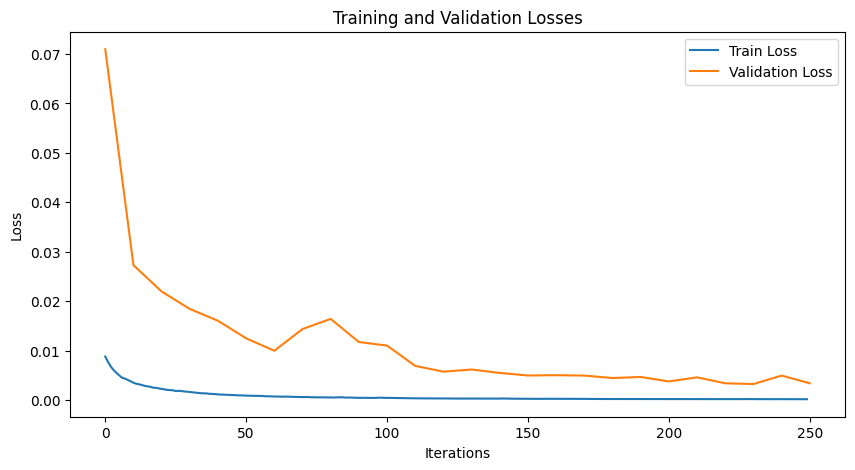

In [26]:
lit_model.plot_losses()

In [27]:
checkpoint_callback.best_model_path

'tb_logs\\cell_unet_model\\version_0\\checkpoints\\checkpoint-cell_seg_unet-epoch=229-val_loss=0.00.ckpt'

In [29]:
best_model = LitUNet.load_from_checkpoint(checkpoint_callback.best_model_path)

In [36]:
val_ds[0]['image'].unsqueeze(0).shape

torch.Size([1, 1, 384, 384])

In [61]:
import monai.networks.utils as m_nn_utils

In [64]:
import onnx
import importlib
importlib.reload(m_nn_utils)


<module 'monai.networks.utils' from 'C:\\Users\\siniz\\AppData\\Roaming\\Python\\Python310\\site-packages\\monai\\networks\\utils.py'>

In [76]:
def enable_running_stats(model, device):
    """Temporarily enable track_running_stats and initialize running statistics."""
    for module in model.modules():
        if isinstance(module, torch.nn.InstanceNorm2d):  # Adjust for InstanceNorm1d/3d if needed
            num_features = module.num_features
            module.running_mean = torch.zeros(num_features, device=device)
            module.running_var = torch.ones(num_features, device=device)
            module.track_running_stats = True

In [83]:
unwrapped_best_model = best_model.model

In [78]:
enable_running_stats(unwrapped_best_model, 'cuda')

In [85]:
with torch.no_grad():
    unwrapped_best_model.eval()
    m_nn_utils.convert_to_onnx(unwrapped_best_model, inputs=[train_ds[0]['image'].unsqueeze(0).cuda()], input_names=["image"], output_names=["mask"], opset_version=21, verify=True, use_ort=True, dynamo=True)#

AssertionError: Tensor-likes are not close!

Mismatched elements: 204569 / 294912 (69.4%)
Greatest absolute difference: 341.375 at index (0, 0, 154, 309) (up to 0.0 allowed)
Greatest relative difference: 0.002427260158583522 at index (0, 0, 11, 260) (up to 0.0001 allowed)